# Desigualdade territorial e desempenho municipal

**Área de análise:** Pará (PA)  
**Referência territorial:** município da escola (ESC)  
**Período disponível:** 1998–2025, conforme disponibilidade de cada fonte e questão.\
**Fontes:** `painel`, `dsp`


**OBJETIVO**

O eixo investiga as diferenças territoriais de desempenho no ENEM, considerando a evolução das médias municipais, a estabilidade dos resultados, a dispersão entre municípios, a evolução acumulada, a presença recorrente nos melhores rankings e a relação entre participação e desempenho.

<div style="background-color: #f5f0dc; padding: 12px; border-radius: 6px;">
    
> **Nota Metodológica**\
O índice de Gini foi usado para sintetizar em um único valor, por ano e disciplina, o grau de desigualdade entre as médias municipais e acompanhar sua evolução, porque, sendo adimensional, permite comparar períodos com escalas de nota diferentes (0–100 até 2008 e 0–1000 a partir de 2009), o que medidas em pontos, como o P90–P10, não permitem. Como a nota não tem zero absoluto, seus valores são baixos e acompanham de perto o CV, por isso ele complementa as demais medidas e não as substitui.
>  </div>

## Principais achados
<div style="background-color: #DBEAFE; padding: 12px; border-radius: 6px;">

> **Aumento da desigualdade relativa em Matemática**  
> O coeficiente de variação (CV) das médias municipais passou de **2,50% em 2009 para 5,84% em 2023**, a maior marca da série nessa disciplina.

> **Recorrência dos melhores resultados em municípios específicos**  
> Belém e Castanhal estiveram no **Top 10 em 100% dos anos entre 2009 e 2023** nas quatro disciplinas CH, CN, LC e MT.

> **Associação positiva entre participação e desempenho**  
> Entre 2009 e 2023, a mediana anual da correlação de Pearson entre o logaritmo do número de participantes e a média municipal variou de **0,583 em Redação a 0,645 em CH**.
 </div>

## Configuração e carga

In [1]:
from _setup2 import *

UF_PROCESSAMENTO = "PA"
TIPO_REFERENCIA = "ESC"

out = read_allfiles2(UF_PROCESSAMENTO, TIPO_REFERENCIA)

painel_esc = out["painel"]["data"].copy()
dsp = out["dsp"]["data"].copy()

N_MINIMO_PARTICIPANTES = 100  # a função aplica .gt(100), isto é, N > 100
ANO_INICIO_PRINCIPAL = 2002
COBERTURA_MINIMA_ESTABILIDADE = 0.70
MINIMO_ANOS_ESTABILIDADE = 10
TOP_N = 10

print("=" * 46)
print(f"UF: {UF_PROCESSAMENTO}  | Período :{painel_esc['ano'].min()}–{painel_esc['ano'].max()}| Referência: {TIPO_REFERENCIA} ")
print("=" * 46)
print(f"painel  : {painel_esc.shape[0]:,} x {painel_esc.shape[1]}".replace(",", "."))
print(f"dsp     : {dsp.shape[0]:,} x {dsp.shape[1]}".replace(",", "."))
print("=" * 46)

UF: PA  | Período :1998–2025| Referência: ESC 
painel  : 3.625 x 82
dsp     : 250.436 x 17


## 1. Como evoluiu o desempenho médio dos municípios paraenses?

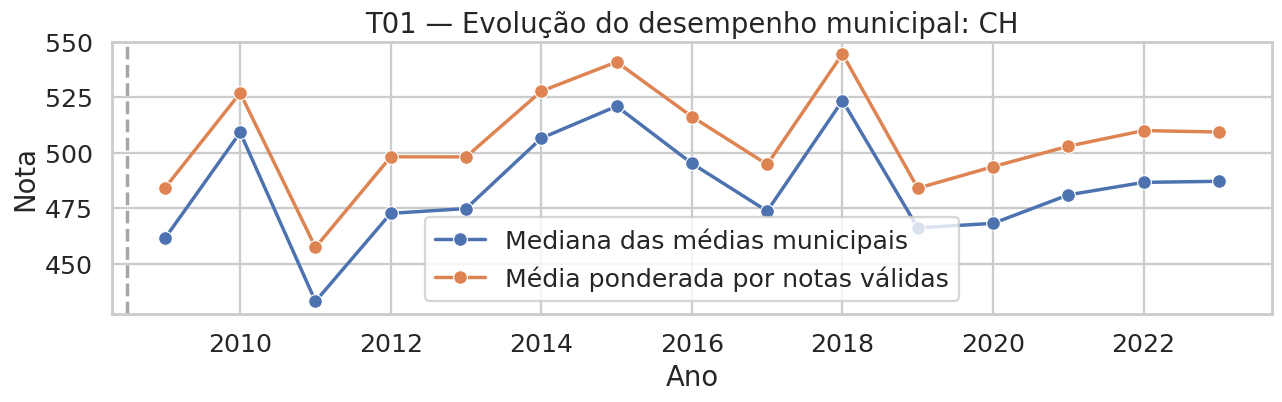

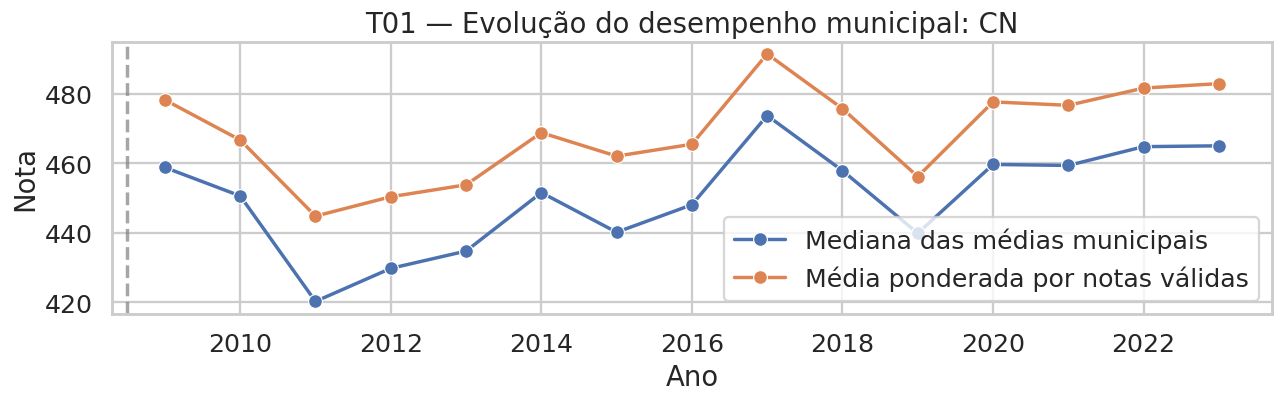

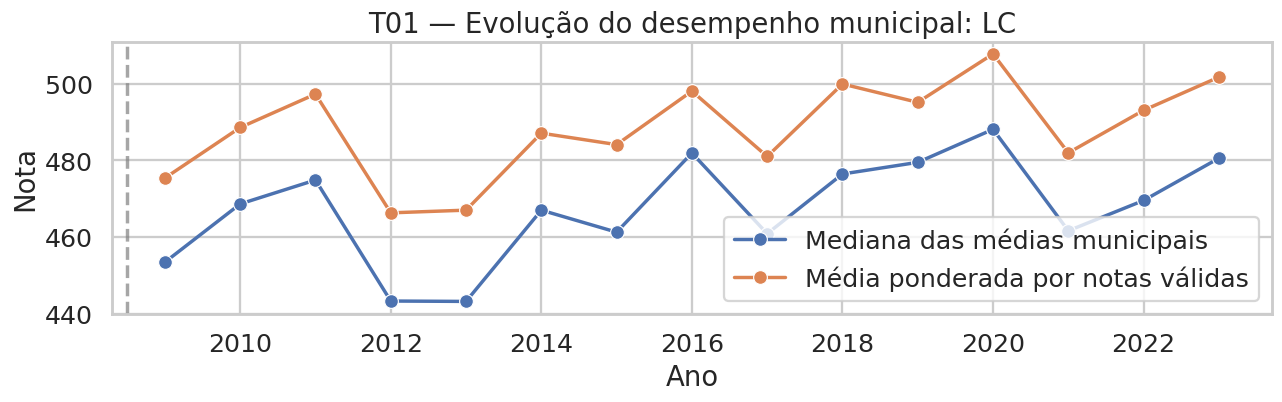

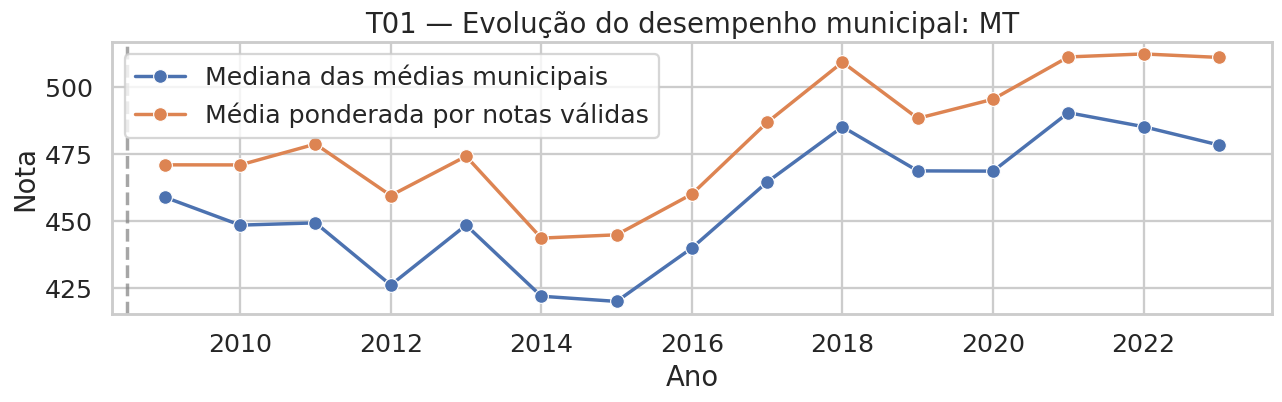

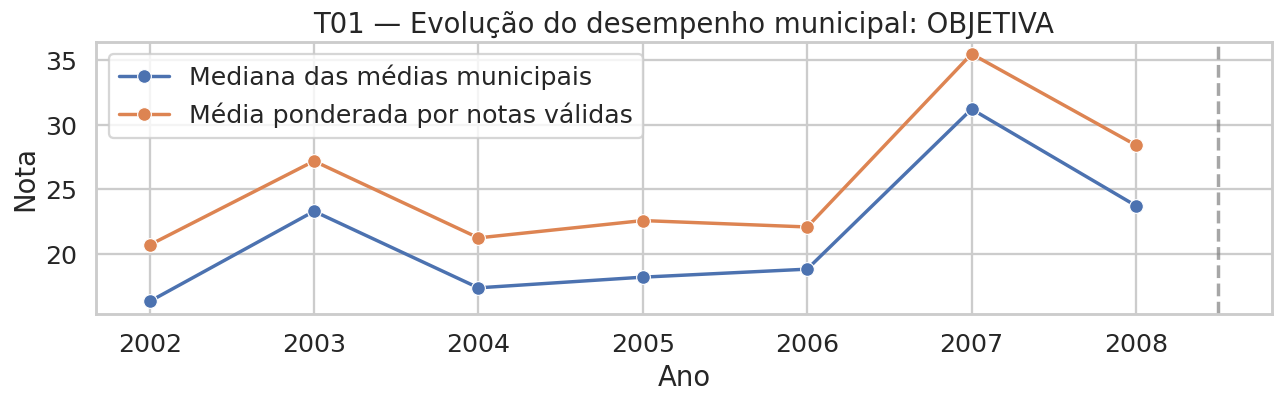

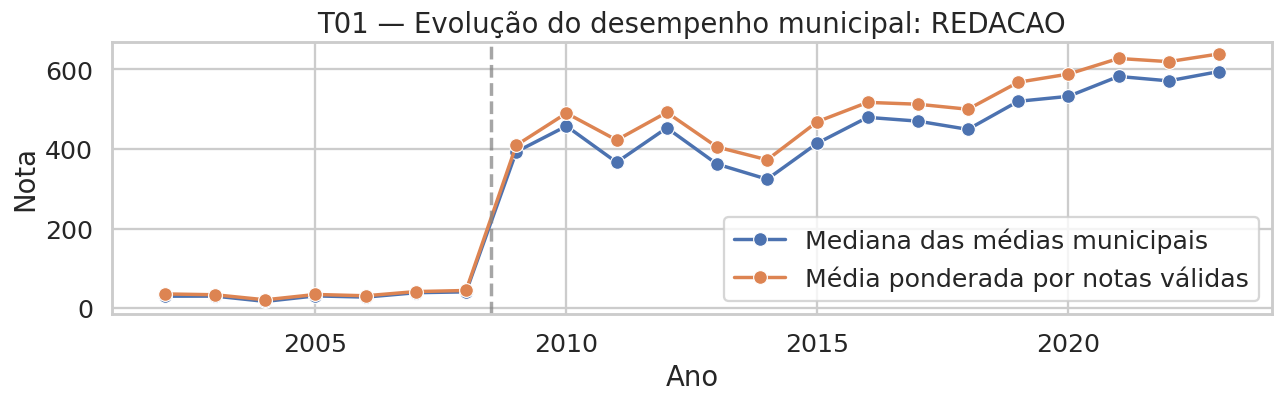

In [2]:
desempenho_municipal = eda2.preparar_desempenho_territorial_dsp(dsp,
    referencia=TIPO_REFERENCIA,
    n_minimo_participantes=N_MINIMO_PARTICIPANTES,
    anos_inicio_comparavel=ANO_INICIO_PRINCIPAL,
    painel=painel_esc)

base_t01 = desempenho_municipal.copy()
base_t01["periodo_analise"] = np.select(
    [
        base_t01["ano"].lt(ANO_INICIO_PRINCIPAL),
        base_t01["elegivel_analise_principal"],
    ],
    ["1998-2001_exploratorio", "2002+_elegivel"],
    default="fora_criterio",
)

serie_t01 = base_t01.loc[
    base_t01["elegivel_analise_principal"]
].groupby(["ano", "disciplina"], as_index=False).agg(
    media_simples_municipios=("media_ponderada", "mean"),
    mediana_municipal=("media_ponderada", "median"),
    std_entre_municipios=("media_ponderada", "std"),
    soma_n_validos=("n_validos", "sum"),
    n_municipios=("CO_MUNICIPIO_TERRITORIO", "nunique"),
)
# Média ponderada estadual reconstruída a partir das médias municipais e n_validos.
somas = desempenho_municipal.loc[
    desempenho_municipal["elegivel_analise_principal"]
].assign(
    soma=lambda d: d["media_ponderada"] * d["n_validos"]
).groupby(["ano", "disciplina"], as_index=False).agg(
    soma_ponderada=("soma", "sum"),
    n_validos=("n_validos", "sum"),
)
serie_t01 = serie_t01.merge(somas, on=["ano", "disciplina"], how="left")
serie_t01["media_ponderada_estadual"] = (
    serie_t01["soma_ponderada"] / serie_t01["n_validos"]
)
#display(serie_t01)

# Série exploratória de 1998–2001: mantida separada devido à baixa adesão.
serie_t01_inicial = base_t01.loc[
    base_t01["periodo_inicial_baixa_adesao"]
].groupby(["ano", "disciplina"], as_index=False).agg(
    media_simples_municipios=("media_ponderada", "mean"),
    mediana_municipal=("media_ponderada", "median"),
    n_municipios=("CO_MUNICIPIO_TERRITORIO", "nunique"),
    n_participantes=("n_participantes", "sum"),
    n_validos=("n_validos", "sum"),
)
#display(serie_t01_inicial)

for disciplina, g in serie_t01.groupby("disciplina"):
    fig, ax = plt.subplots(figsize=(12, 4))
    sns.lineplot(data=g, x="ano", y="mediana_municipal", marker="o", ax=ax,
                 label="Mediana das médias municipais")
    sns.lineplot(data=g, x="ano", y="media_ponderada_estadual", marker="o", ax=ax,
                 label="Média ponderada por notas válidas")
    ax.set(title=f"T01 — Evolução do desempenho municipal: {disciplina}",
           xlabel="Ano", ylabel="Nota")
    ax.axvline(2008.5, color="gray", linestyle="--", alpha=.7)
    plt.tight_layout()
    plt.show()


### Comentários

A série principal mostra a evolução das médias municipais elegíveis e da média ponderada estadual. Para a leitura comparável entre disciplinas, o período mais adequado é 2009–2023, quando o exame passa a apresentar as áreas CH, CN, LC e MT, além da Redação, em uma escala próxima de 0–1000.

Entre 2009 e 2023, a média ponderada estadual apresentou os seguintes valores:

| Disciplina | 2009  | 2023  | Variação em pontos |
| ---------- | -----:| -----:| ------------------:|
| CH         | 484,1 | 509,4 | +25,2              |
| CN         | 478,3 | 483,0 | +4,7               |
| LC         | 475,4 | 501,7 | +26,3              |
| MT         | 470,9 | 511,0 | +40,2              |
| Redação    | 409,3 | 638,9 | +229,5             |


A maior elevação nominal ocorreu na Redação, seguida por Matemática. Ciências da Natureza apresentou a menor variação entre os dois extremos. Essas diferenças devem ser lidas com atenção às oscilações anuais e às mudanças de cobertura municipal. A quantidade de municípios elegíveis também variou. Em 2009 eram 57; o número cresceu até alcançar 108 em 2016 e 2017, mas recuou para 58 em 2023. Portanto, a média de cada ano não representa exatamente o mesmo conjunto de municípios.

Os resultados indicam elevação das médias ponderadas entre 2009 e 2023, mais expressiva em Redação e Matemática. Entretanto, a trajetória não foi linear e a cobertura municipal diminuiu nos anos finais. A evolução estadual não deve ser interpretada como melhoria uniforme em todos os municípios. No período anterior a 2009, a série exploratória apresenta somente os anos de 2001 a 2008 para `OBJETIVA` e `REDAÇÃO` (2001 aparece em uma tabela separada). Esses valores não devem ser unidos às séries posteriores devido à mudança de escala e à reorganização do exame.


## 2. Quais municípios apresentam maior estabilidade de desempenho?

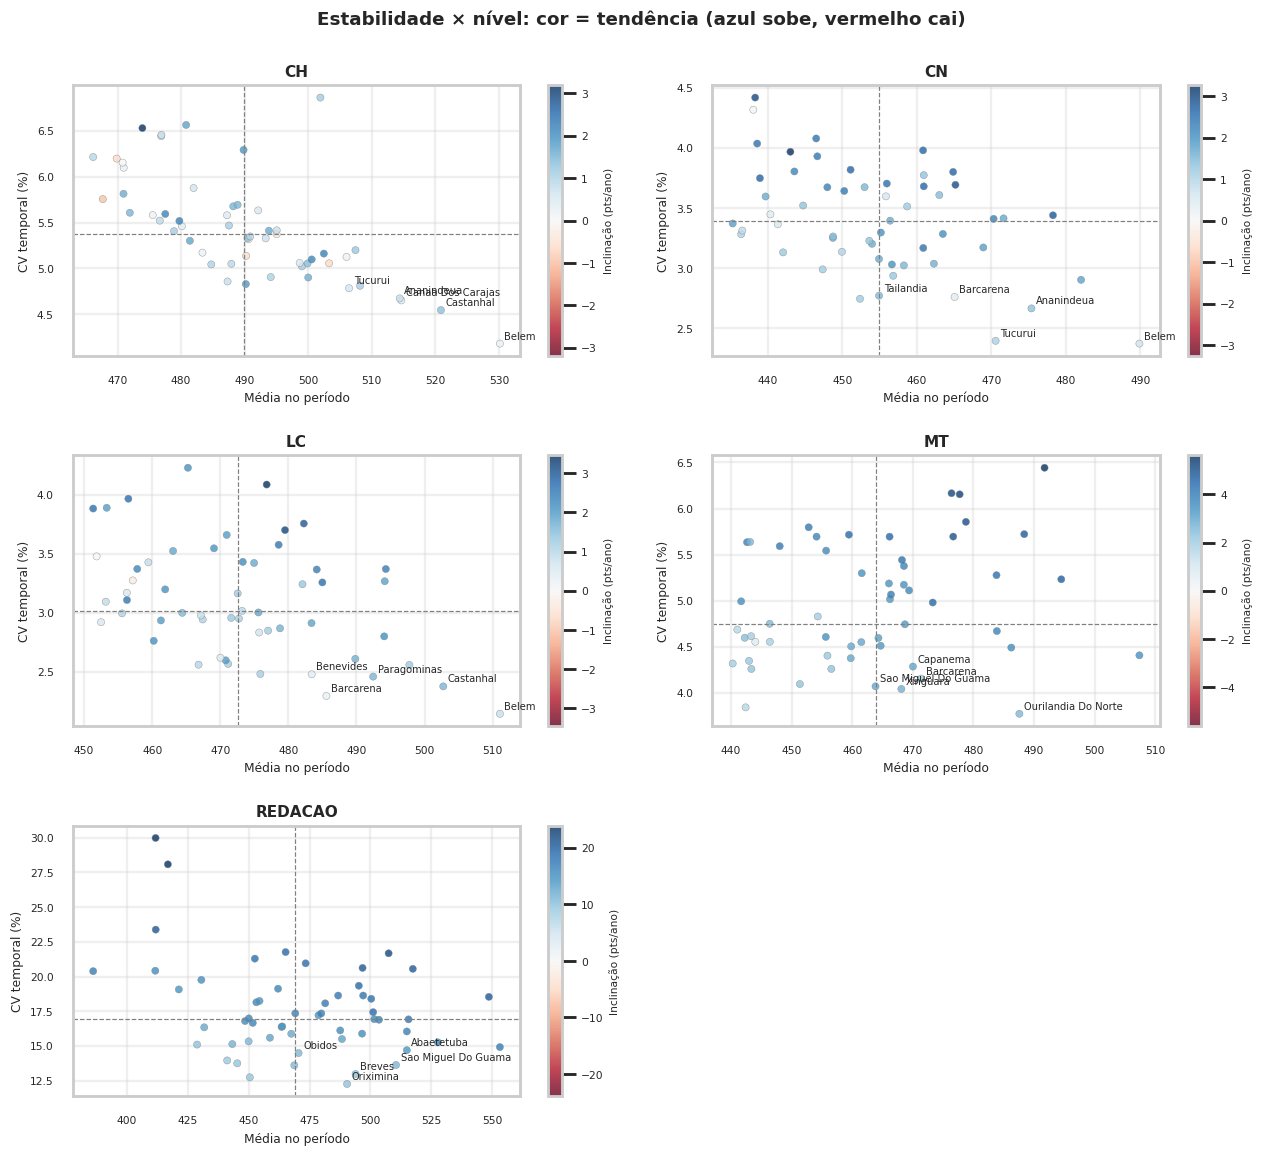

In [3]:
ANO_INICIO_ESTAB = 2009   # início do Enem com escala 0-1000
ano_final_dsp=2025
estab = eda2.calcular_estabilidade_municipal(
    desempenho_municipal,
    ano_inicio=ANO_INICIO_ESTAB,
    ano_fim=ano_final_dsp,
    cobertura_minima=COBERTURA_MINIMA_ESTABILIDADE,
    minimo_anos=MINIMO_ANOS_ESTABILIDADE,
)
estab["NOME"] = estab["NO_MUNICIPIO_TERRITORIO"].str.title()
#print(estab.groupby("disciplina").size())   # confira se todas as disciplinas ficaram com municípios

discs = [d for d in ["CH", "CN", "LC", "MT", "REDACAO"] if d in estab.disciplina.unique()]
TOP = 15
ncols = 2
nrows = -(-len(discs) // ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(12, 3.6 * nrows), squeeze=False)

for ax, disc in zip(axes.flat, discs):
    s = estab[estab.disciplina == disc]
    #display(s)
    sc = ax.scatter(s.media_periodo, s.cv_temporal_pct, c=s.inclinacao_pontos_ano,
                    cmap="RdBu", vmin=-s.inclinacao_pontos_ano.abs().max(),
                    vmax=s.inclinacao_pontos_ano.abs().max(), s=22, alpha=0.8,
                    edgecolor="gray", linewidth=0.3)
    ax.axvline(s.media_periodo.median(), color="gray", ls="--", lw=0.8)
    ax.axhline(s.cv_temporal_pct.median(), color="gray", ls="--", lw=0.8)
    # rotula os 5 mais estáveis entre os de nota acima da mediana
    dest = s[s.media_periodo >= s.media_periodo.median()].nsmallest(5, "cv_temporal_pct")
    for _, r in dest.iterrows():
        ax.annotate(r.NOME, (r.media_periodo, r.cv_temporal_pct), fontsize=6.5,
                    xytext=(3, 3), textcoords="offset points")
    ax.set_title(disc, fontsize=10, fontweight="bold")
    ax.set_xlabel("Média no período", fontsize=8)
    ax.set_ylabel("CV temporal (%)", fontsize=8)
    ax.tick_params(labelsize=7); ax.grid(alpha=0.3)
    cb = fig.colorbar(sc, ax=ax); cb.set_label("Inclinação (pts/ano)", fontsize=7)
    cb.ax.tick_params(labelsize=7)

for ax in axes.flat[len(discs):]:
    ax.set_visible(False)

fig.suptitle("Estabilidade × nível: cor = tendência (azul sobe, vermelho cai)",
             fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

### Comentários:
Para evitar a mistura de escalas, a leitura comparável foi recalculada a partir da base municipal completa, considerando 2009–2023, N > 100, pelo menos 10 anos observados e cobertura mínima de 70% da janela. Com esses critérios, foram identificados 57 municípios por disciplina.

A estabilidade temporal, medida pelo coeficiente de variação (CV) das médias anuais municipais, apresentou as seguintes medianas entre municípios:

| Disciplina | CV temporal mediano | Amplitude temporal mediana (pontos) | Inclinação mediana (pontos/ano) |
| ---------- | ------------------- | ----------------------------------- | ------------------------------- |
| CH         | 5,41%               | 93,21                               | 0,91                            |
| CN         | 3,41%               | 56,42                               | 1,64                            |
| LC         | 3,01%               | 45,52                               | 1,61                            |
| MT         | 4,75%               | 73,67                               | 3,32                            |
| Redação    | 16,93%              | 264,02                              | 15,34                           |

*Estatísticas calculadas sobre as séries municipais elegíveis entre 2009 e 2023. A inclinação é descritiva e não significa crescimento contínuo em todos os anos.*

LC e CN apresentaram os menores CVs temporais medianos, indicando maior estabilidade relativa das médias municipais ao longo da janela. Redação apresentou a maior variação temporal, tanto em CV quanto em amplitude. Parte dessa diferença decorre da maior amplitude de pontuação observada na Redação, razão pela qual a comparação entre disciplinas deve priorizar o CV, e ainda assim ser interpretada com cautela.

**Municípios mais e menos estáveis por disciplina (menor e maior CV temporal):**

| Disciplina | Mais estáveis (CV)                                              | Menos estáveis (CV)                                                     |
| ---------- | --------------------------------------------------------------- | ----------------------------------------------------------------------- |
| CH         | Belém (4,18%), Castanhal (4,54%), Canaã dos Carajás (4,65%)     | Novo Progresso (6,86%), Santa Maria do Pará (6,60%), Mãe do Rio (6,57%) |
| CN         | Belém (2,37%), Tucuruí (2,40%), Ananindeua (2,67%)              | Monte Alegre (4,42%), Breu Branco (4,32%), Soure (4,10%)                |
| LC         | Belém (2,14%), Barcarena (2,29%), Castanhal (2,38%)             | Mãe do Rio (4,23%), Tucumã (4,09%), Óbidos (3,96%)                      |
| MT         | Ourilândia do Norte (3,77%), Mocajuba (3,84%), Xinguara (4,04%) | Canaã dos Carajás (6,44%), Itaituba (6,17%), Marabá (6,15%)             |
| Redação    | Oriximiná (12,26%), Curuçá (12,74%), Breves (12,98%)            | Novo Repartimento (29,98%), Acará (28,08%), Concórdia do Pará (23,38%)  |

Em CH, CN e LC, os municípios de maior porte (Belém, Castanhal, Ananindeua, Tucuruí) concentram-se entre os mais estáveis, o que é compatível com menor ruído amostral em médias calculadas sobre mais participantes. Em MT e Redação esse padrão não se repete: o topo de estabilidade é ocupado por municípios de médias intermediárias ou baixas, como Mocajuba (média de 442 pontos em MT) e Oriximiná. Em MT e Redação, os municípios com maior CV também tendem a ter maior inclinação (Canaã dos Carajás: 5,62 pontos/ano em MT e 21,82 na Redação; Acará: 23,94 na Redação). Isso indica que parte da instabilidade medida reflete tendência de variação ao longo do período, e não apenas oscilação sem direção.

Alguns municípios entram na análise com cobertura menor que a janela completa (11 a 12 anos observados), como Soure, Santa Maria do Pará, Breu Branco e Rondon do Pará. Seus CVs devem ser lidos com mais cautela.

Entre 2009 e 2023, as médias municipais de LC e CN foram relativamente mais estáveis, e Belém foi o município mais estável em CH, CN e LC. Redação apresentou maior oscilação temporal, com municípios de CV superior a 20% associados também a maiores inclinações. A estabilidade não deve ser confundida com nível de desempenho: um município pode manter uma média estável em patamar baixo ou alto. O CV temporal também não separa oscilação de tendência, de modo que municípios com melhora consistente podem aparecer como menos estáveis.


## 3. A diferença de desempenho entre municípios aumentou ou diminuiu?


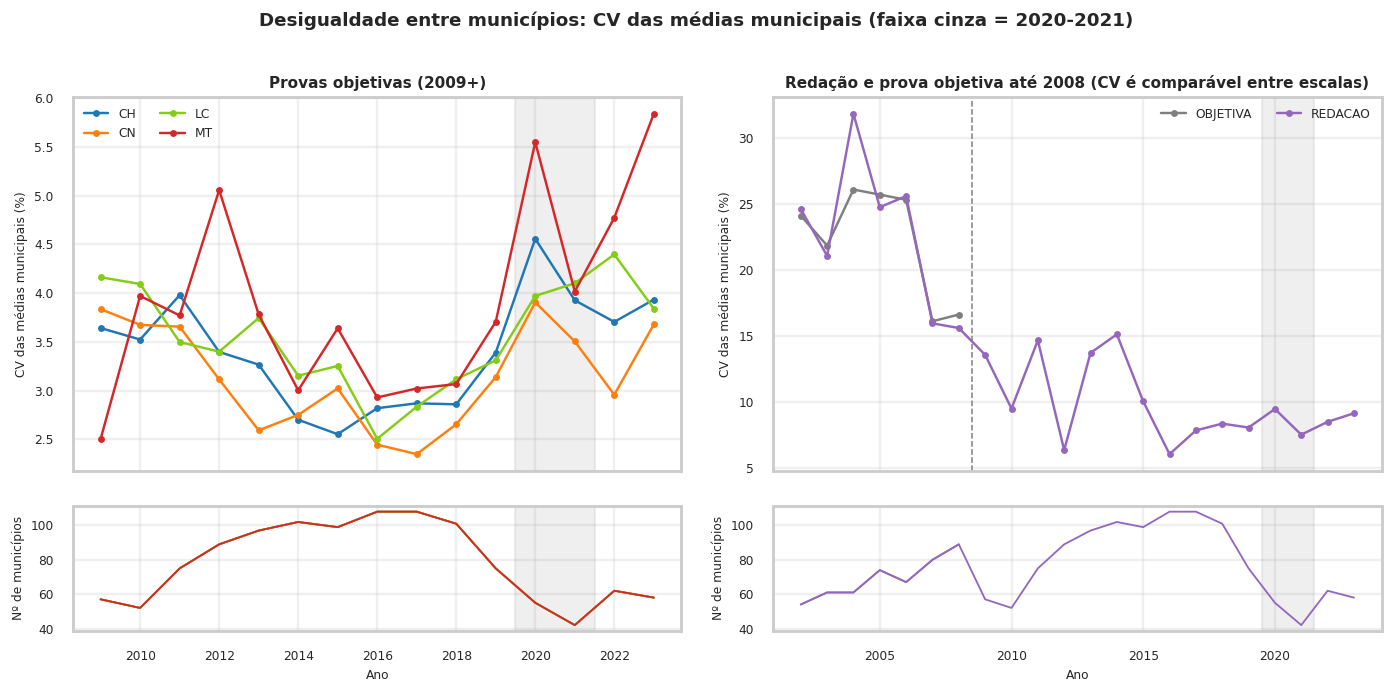

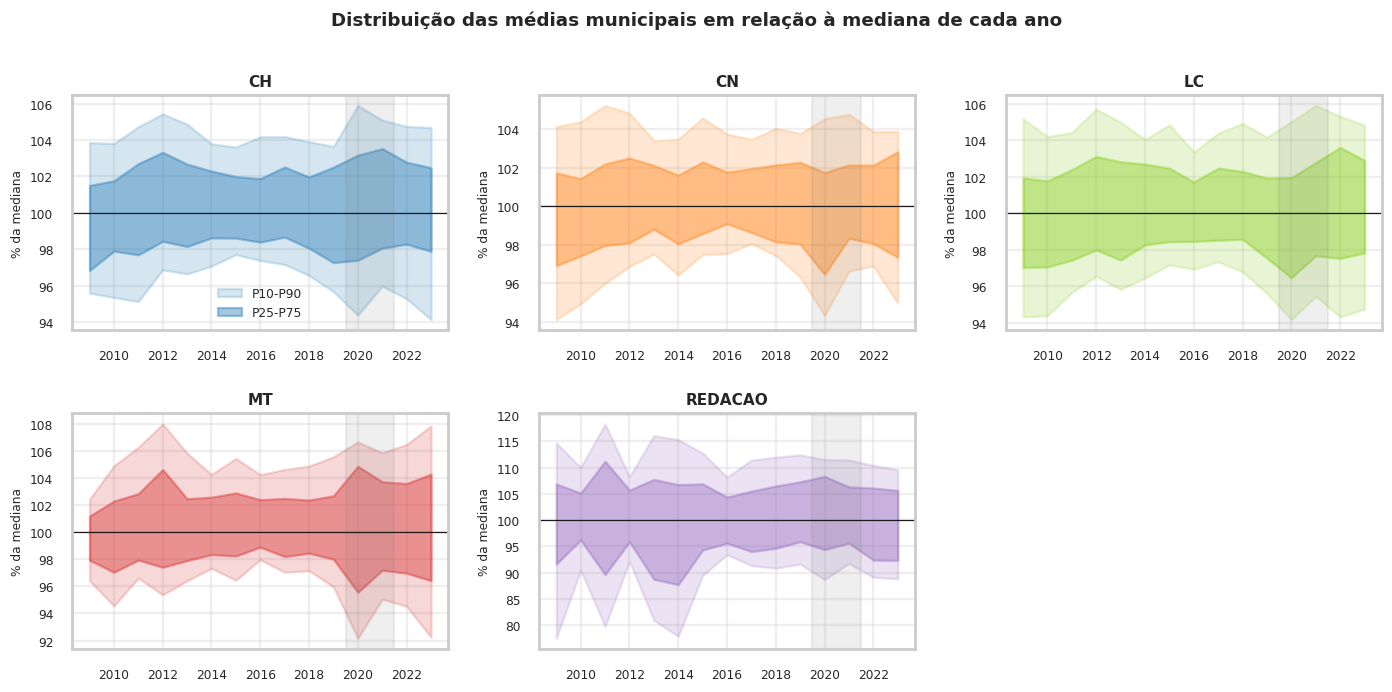

In [4]:
desigualdade_t03 = eda2.calcular_indicadores_desigualdade_territorial(
    desempenho_municipal, usar_elegiveis=True
)
t = desigualdade_t03.sort_values(["disciplina", "ano"]).copy()
t["p90_p10_rel"] = (t["q90"] - t["q10"]) / t["mediana_municipal"] * 100
t["iqr_rel"] = t["iqr"] / t["mediana_municipal"] * 100

CORES = {"CH": "#1f77b4", "CN": "#ff7f0e", "LC": "#84cc16", "MT": "#d62728", "REDACAO": "#9467bd", "OBJETIVA": "#7f7f7f"}

objetivas = ["CH", "CN", "LC", "MT"]

fig, axes = plt.subplots(2, 2, figsize=(13, 6.5), sharex="col",
                         gridspec_kw={"height_ratios": [3, 1]})

for disc in objetivas:
    s = t[t.disciplina == disc]
    axes[0, 0].plot(s.ano, s.cv_municipal_pct, marker="o", ms=3.5, lw=1.6, color=CORES[disc], label=disc)
    axes[1, 0].plot(s.ano, s.n_municipios, lw=1.2, color=CORES[disc])
axes[0, 0].set_title("Provas objetivas (2009+)", fontsize=10, fontweight="bold")

for disc in ["OBJETIVA", "REDACAO"]:
    s = t[t.disciplina == disc]
    axes[0, 1].plot(s.ano, s.cv_municipal_pct, marker="o", ms=3.5, lw=1.6,
                    color=CORES[disc], label=disc)
    axes[1, 1].plot(s.ano, s.n_municipios, lw=1.2, color=CORES[disc])
axes[0, 1].axvline(2008.5, color="gray", ls="--", lw=1)
axes[0, 1].set_title("Redação e prova objetiva até 2008 (CV é comparável entre escalas)",
                     fontsize=10, fontweight="bold")

for ax in axes[0]:
    ax.axvspan(2019.5, 2021.5, color="gray", alpha=0.12)
    ax.set_ylabel("CV das médias municipais (%)", fontsize=8)
    ax.legend(frameon=False, fontsize=8, ncol=2); ax.grid(alpha=0.3)
for ax in axes[1]:
    ax.axvspan(2019.5, 2021.5, color="gray", alpha=0.12)
    ax.set_ylabel("Nº de municípios", fontsize=8); ax.set_xlabel("Ano", fontsize=8)
    ax.grid(alpha=0.3)
for ax in axes.flat:
    ax.tick_params(labelsize=8)
fig.suptitle("Desigualdade entre municípios: CV das médias municipais (faixa cinza = 2020-2021)",
             fontsize=12, fontweight="bold")
plt.tight_layout(); plt.show()

discs = objetivas + ["REDACAO"]
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5), squeeze=False)

for ax, disc in zip(axes.flat, discs):
    s = t[(t.disciplina == disc) & (t.ano >= 2009)]
    m = s["mediana_municipal"]
    ax.fill_between(s.ano, s.q10 / m * 100, s.q90 / m * 100, color=CORES[disc], alpha=0.18, label="P10-P90")
    ax.fill_between(s.ano, s.q25 / m * 100, s.q75 / m * 100, color=CORES[disc], alpha=0.40, label="P25-P75")
    ax.axhline(100, color="k", lw=0.8)
    ax.set_title(disc, fontsize=10, fontweight="bold")
    ax.axvspan(2019.5, 2021.5, color="gray", alpha=0.12)
    ax.tick_params(labelsize=8); ax.grid(alpha=0.3)
    ax.set_ylabel("% da mediana", fontsize=8)
axes.flat[0].legend(frameon=False, fontsize=8)
axes.flat[-1].set_visible(False)
fig.suptitle("Distribuição das médias municipais em relação à mediana de cada ano",
             fontsize=12, fontweight="bold")
plt.tight_layout(); plt.show()

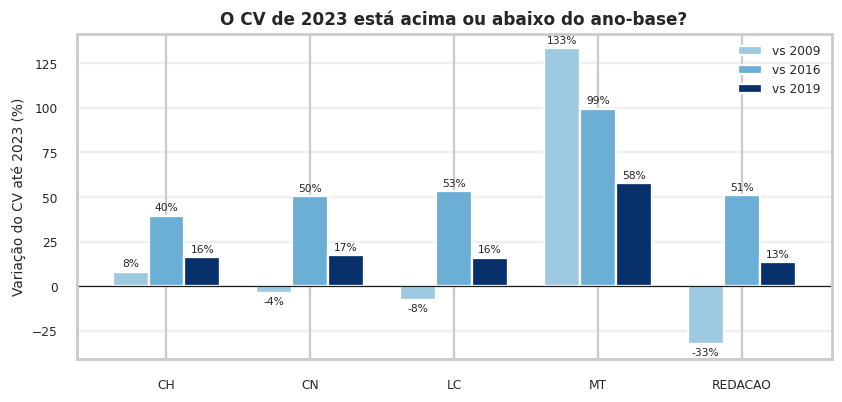

In [5]:
bases = [2009, 2016, 2019]
piv = t.pivot(index="disciplina", columns="ano", values="cv_municipal_pct")
piv = piv.loc[["CH", "CN", "LC", "MT", "REDACAO"]]
var = pd.DataFrame({f"vs {b}": (piv[2023] / piv[b] - 1) * 100 for b in bases})

ax = var.plot(kind="bar", figsize=(8, 4), width=0.75,
              color=["#9ecae1", "#6baed6", "#08306b"])
ax.axhline(0, color="k", lw=0.8)
ax.set_ylabel("Variação do CV até 2023 (%)", fontsize=9)
ax.set_xlabel("")
ax.set_title("O CV de 2023 está acima ou abaixo do ano-base?", fontsize=11, fontweight="bold")
ax.tick_params(labelsize=8, axis="x", rotation=0); ax.tick_params(labelsize=8, axis="y")
ax.legend(frameon=False, fontsize=8, title="")
ax.grid(axis="y", alpha=0.3)
for c in ax.containers:
    ax.bar_label(c, fmt="%.0f%%", fontsize=7, padding=2)
plt.tight_layout(); plt.show()

### Comentários

A dispersão foi calculada anualmente entre as médias dos municípios elegíveis (N > 100). São considerados desvio-padrão, coeficiente de variação (CV), Gini das médias municipais e distância entre os percentis 90 e 10 (P90–P10). Como a escala da nota mudou em 2009 (0–100 até 2008, 0–1000 depois), a evolução ao longo do tempo é lida pelo CV e pelo Gini. O P90–P10 e o desvio-padrão, em pontos, só são comparáveis dentro de 2009–2023.

Em 2023, os indicadores foram:

| Disciplina | Municípios | Desvio-padrão | CV    | Gini   | P90–P10 |
| ---------- | ---------- | ------------- | ----- | ------ | ------- |
| CH         | 58         | 19,18         | 3,93% | 0,0219 | 51,43   |
| CN         | 58         | 17,10         | 3,68% | 0,0206 | 41,43   |
| LC         | 58         | 18,50         | 3,84% | 0,0217 | 48,34   |
| MT         | 58         | 28,03         | 5,84% | 0,0330 | 74,54   |
| Redação    | 58         | 53,95         | 9,16% | 0,0511 | 123,16  |

A Redação apresentou a maior dispersão absoluta e relativa entre as médias municipais em 2023. Matemática aparece em seguida, com CV de 5,84% e P90–P10 de 74,54 pontos. Ciências da Natureza apresentou a menor dispersão relativa, com CV de 3,68%.

**Evolução do CV (2009–2023)**

O resultado depende do ano de partida. Por isso, o CV de 2023 foi comparado com três anos-base: 2009 (início da série), 2016 (menor dispersão na maioria das áreas) e 2019 (pré-pandemia).

| Disciplina | CV 2009 | CV 2016 | CV 2019 | CV 2023 | Δ vs 2009 | Δ vs 2016 | Δ vs 2019 | Mínimo da série | Máximo da série |
| ---------- | ------- | ------- | ------- | ------- | --------- | --------- | --------- | --------------- | --------------- |
| CH         | 3,64%   | 2,82%   | 3,39%   | 3,93%   | +8%       | +40%      | +16%      | 2,55% (2015)    | 4,56% (2020)    |
| CN         | 3,84%   | 2,45%   | 3,14%   | 3,68%   | −4%       | +50%      | +17%      | 2,35% (2017)    | 3,91% (2020)    |
| LC         | 4,16%   | 2,50%   | 3,31%   | 3,84%   | −8%       | +53%      | +16%      | 2,50% (2016)    | 4,40% (2022)    |
| MT         | 2,50%   | 2,93%   | 3,71%   | 5,84%   | +133%     | +99%      | +58%      | 2,50% (2009)    | 5,84% (2023)    |
| Redação    | 13,57%  | 6,07%   | 8,08%   | 9,16%   | −33%      | +51%      | +13%      | 6,07% (2016)    | 15,13% (2014)   |

- CH: o CV passou de 3,64% para 3,93% entre 2009 e 2023, aumento moderado. Em relação a 2016 e 2019, a alta é maior.
- CN: passou de 3,84% para 3,68%, pequena redução em relação a 2009. O menor valor da série foi 2,35% em 2017.
- LC: passou de 4,16% para 3,84%, também uma redução em relação a 2009. O CV chegou a 4,40% em 2022.
- MT: passou de 2,50% para 5,84%, aumento expressivo. 2023 é o maior CV da série e 2009 o menor, de modo que a comparação com 2009 amplia a mudança. Ainda assim, a alta persiste contra 2016 (+99%) e 2019 (+58%).
- Redação: o CV passou de 13,57% para 9,16%, e o P90–P10 caiu de 145,68 para 123,16 pontos. A dispersão diminuiu tanto em termos relativos quanto absolutos em relação a 2009. No período anterior (2002–2008, escala 0–100), o CV já havia caído de 24,6% para 15,6%.

**Distribuição das médias municipais em relação à mediana**

Na Redação, o intervalo P10–P90 passou de 37,1 para 20,7 pontos percentuais da mediana entre 2009 e 2023, com o menor valor em 2016 (14,7 p.p.). Nas provas objetivas, o intervalo P10–P90 passou, entre 2009 e 2023, de 8,3 para 10,6 p.p. em CH, de 10,0 para 8,9 em CN, de 10,8 para 10,1 em LC e de 6,0 para 15,6 em MT. Em MT, a abertura vem das duas pontas: o P10 caiu de 96,4% para 92,3% da mediana, e o P90 subiu de 102,4% para 107,8%. Em CH, o P10 recuou de 95,6% para 94,1%, o que sugere que a cauda inferior se afastou um pouco mais.

Não existe uma tendência única de desigualdade territorial para todas as disciplinas. A leitura de longo prazo é de queda da dispersão até 2015–2017, seguida de alta, com pico em 2020 em CH, CN e MT, e de 2022 em LC. Em 2023 CH, CN, LC e Redação ficam abaixo de seus níveis de 2009, com exceção de CH (+8%), mas bem acima das mínimas de 2016. MT é a exceção: o CV continua subindo e é o único em que 2023 supera todos os anos anteriores. A Redação reduziu a dispersão desde 2009, mas continua sendo a mais desigual entre as disciplinas.

**OBSERVAÇÃO:** o número de municípios elegíveis variou de 108 (2016) para 42 (2021) e 58 (2023), e o CV oscila mais quando há menos municípios, em especial em 2020–2021. Parte do aumento desde 2016 pode, portanto, refletir a mudança de composição e não só maior desigualdade real. A confirmação exige o CV calculado sobre um painel fixo de municípios.

O Gini das médias municipais deve ser lido como indicador complementar. Seus valores são baixos porque medem desigualdade relativa entre médias de notas, que têm uma faixa de variação limitada em relação ao nível médio. Ele acompanha o CV quase proporcionalmente (Gini ≈ 0,0055 × CV), então não traz informação independente e não substitui a leitura conjunta de CV e P90–P10.


## 4. Quais municípios apresentaram maior evolução no desempenho?

A variação acumulada compara o ano inicial de referência (2002) com o último ano disponível no DSP, mantendo apenas municípios elegíveis nos dois extremos. A comparação é feita separadamente por disciplina. Se um município não atender ao critério em um dos extremos, ele não entra no cálculo da variação acumulada.

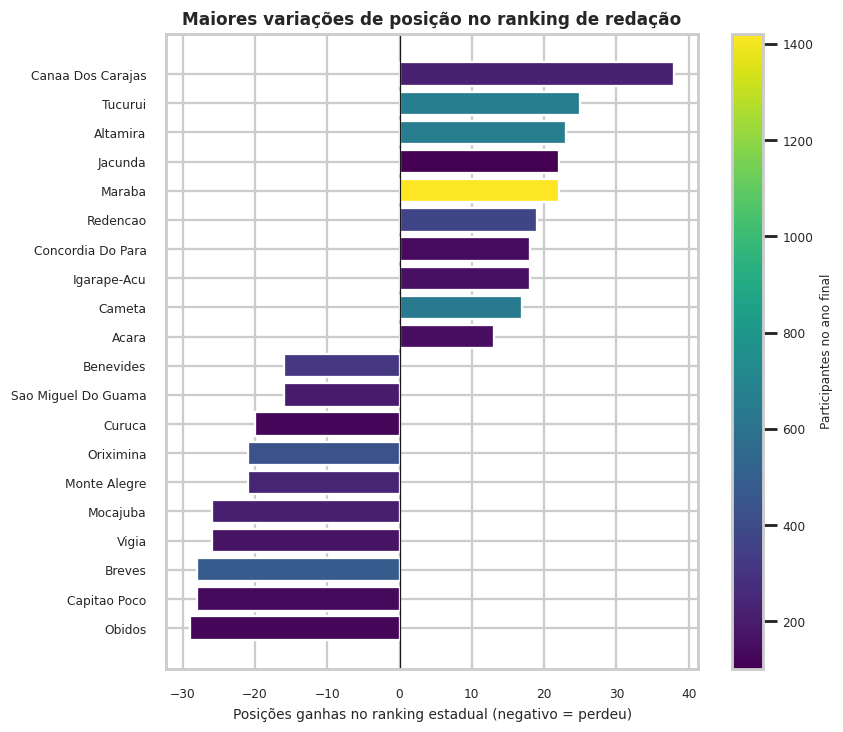

In [6]:
evolucao_t04 = eda2.calcular_evolucao_desempenho_municipal(desempenho_municipal,ano_inicial=2009,ano_final=2023)

e = evolucao_t04.copy()
e = e[e.disciplina == "REDACAO"].copy()      # ajuste se tiver outras disciplinas

# Padroniza dentro de cada ano (comparável mesmo com escalas diferentes)
e["z_inicial"] = (e.media_inicial - e.media_inicial.mean()) / e.media_inicial.std()
e["z_final"]   = (e.media_final   - e.media_final.mean())   / e.media_final.std()
e["delta_z"]   = e.z_final - e.z_inicial

# Ranking (1 = melhor)
e["rank_inicial"] = e.media_inicial.rank(ascending=False)
e["rank_final"]   = e.media_final.rank(ascending=False)
e["delta_rank"]   = e.rank_inicial - e.rank_final    # positivo = subiu no ranking

# Filtro de confiabilidade (ajuste o mínimo)
MIN_N = 20
e = e[(e.n_participantes_inicial >= MIN_N) & (e.n_participantes_final >= MIN_N)]

top = e.nlargest(15, "delta_z").sort_values("delta_z")

sel = pd.concat([e.nlargest(10, "delta_rank"), e.nsmallest(10, "delta_rank")]) \
        .drop_duplicates("CO_MUNICIPIO_TERRITORIO").sort_values("delta_rank")
fig, ax = plt.subplots(figsize=(8, 7))
norm = plt.Normalize(sel.n_participantes_final.min(), sel.n_participantes_final.max())
cores = plt.cm.viridis(norm(sel.n_participantes_final))
ax.barh(sel.NO_MUNICIPIO_TERRITORIO.str.title(), sel.delta_rank, color=cores)
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("Posições ganhas no ranking estadual (negativo = perdeu)", fontsize=9)
ax.set_title("Maiores variações de posição no ranking de redação", fontsize=11, fontweight="bold")
ax.tick_params(labelsize=8)
sm = plt.cm.ScalarMappable(cmap="viridis", norm=norm); sm.set_array([])
cb = plt.colorbar(sm, ax=ax); cb.set_label("Participantes no ano final", fontsize=8)
cb.ax.tick_params(labelsize=8)
plt.tight_layout(); plt.show()

### Comentários
A comparação foi realizada entre 2009 e 2023, mantendo a mesma estrutura de exame e a mesma escala. Foram considerados os municípios elegíveis nos dois anos, totalizando 48 municípios por disciplina. Para a análise comparativa, também foram considerados os municípios com pelo menos 20 participantes em cada ano.

| Disciplina | Municípios comuns | Variação mediana (pontos) | Variação média (pontos) | Menor variação | Maior variação |
| ---------- | ----------------- | ------------------------- | ----------------------- | -------------- | -------------- |
| CH         | 48                | +30,15                    | +28,76                  | -3,43          | +56,53         |
| CN         | 48                | +9,93                     | +9,15                   | -16,37         | +34,85         |
| LC         | 48                | +30,72                    | +29,75                  | -0,82          | +55,47         |
| MT         | 48                | +20,50                    | +24,40                  | -12,68         | +62,01         |
| Redação    | 48                | +200,51                   | +204,20                 | +112,41        | +318,22        |

A maior evolução mediana em pontos ocorreu na Redação, seguida por LC e CH. Em CN, o ganho mediano foi mais modesto. Apesar da evolução positiva das medianas, foram observadas variações negativas em alguns municípios de CH, CN, LC e MT. Na Redação, todos os municípios comuns apresentaram aumento das médias entre 2009 e 2023.

A comparação das posições relativas dos municípios acrescenta outra dimensão aos resultados. Considerando a variação no ranking (`delta_rank`), destacam-se:

- **CH:** Acará (+20 posições), Tailândia (+18) e Dom Eliseu (+17).

- **CN:** Abaetetuba (+23 posições), Óbidos (+20) e Salinópolis (+14).

- **LC:** Dom Eliseu (+23 posições), Salinópolis (+18) e Redenção (+12).

- **MT:** Dom Eliseu (+17 posições), Tailândia e Cametá (+15 cada).

- **Redação:** Canaã dos Carajás (+38 posições), Tucuruí (+25) e Altamira (+23).

Também foram observadas perdas expressivas de posição relativa. Breves apresentou uma das maiores quedas em CH (-26 posições), CN (-26), LC (-24) e MT (-27). Em Redação, Óbidos teve a maior queda entre os municípios destacados (-29 posições).

**Interpretação:** a evolução do desempenho entre 2009 e 2023 foi positiva na maioria dos municípios, mas não ocorreu de maneira uniforme. A Redação apresentou os maiores ganhos absolutos, tanto na variação mediana quanto na média, enquanto CN registrou os menores ganhos centrais. A análise dos rankings evidencia mudanças na posição relativa dos municípios: alguns avançaram significativamente, como Canaã dos Carajás em Redação e Abaetetuba em CN, enquanto outros perderam posições, como Breves em diferentes disciplinas.

Esses resultados mostram que o aumento das médias não implica necessariamente melhora da posição relativa de um município. Da mesma forma, a mudança no ranking depende do desempenho dos demais municípios e não representa, isoladamente, uma medida de crescimento da nota. Por fim, a comparação descreve a diferença entre dois anos de referência, não permitindo afirmar que a evolução ocorreu continuamente ao longo do período.


## 5. Existe concentração territorial dos melhores resultados?

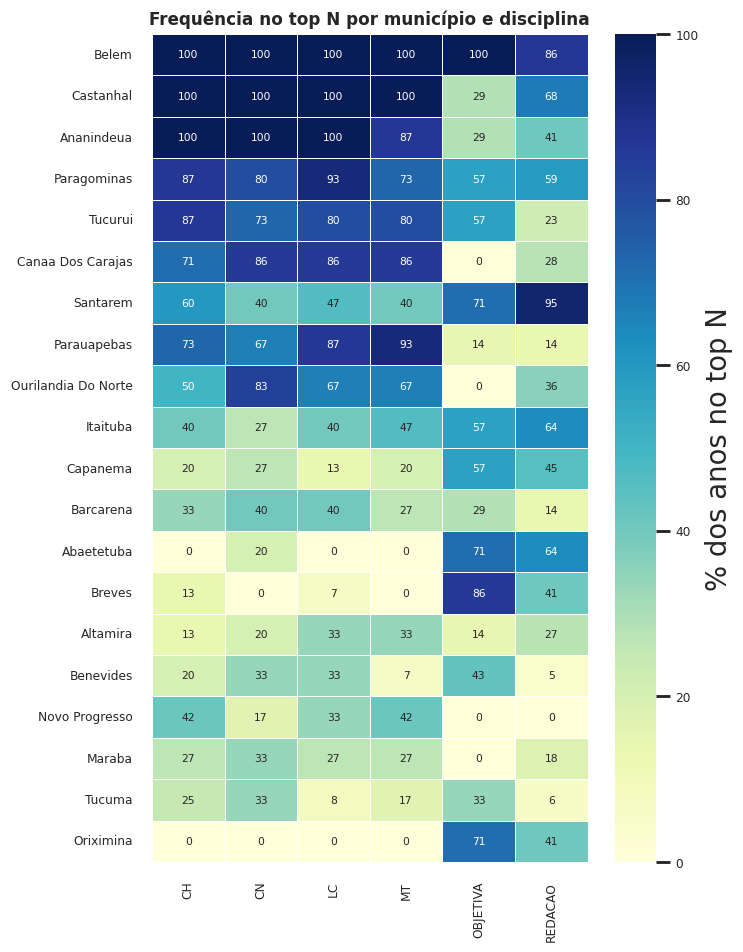

In [7]:
pd.set_option('display.max_rows', None)
# Opcional: exibir todas as colunas também
pd.set_option('display.max_columns', None)

ranking_t05, frequencia_top_t05 = eda2.calcular_ranking_territorial(
    desempenho_municipal, top_n=TOP_N)

#display(ranking_t05.loc[ranking_t05.ano.eq(ano_final_dsp)].groupby("disciplina").head(TOP_N))
r = ranking_t05.copy()
r["NOME"] = r["NO_MUNICIPIO_TERRITORIO"].str.title()

freq = (r.groupby(["NOME", "disciplina"])["top_n"].mean()
          .unstack("disciplina").fillna(0))
freq["total"] = freq.mean(axis=1)
freq = freq.sort_values("total", ascending=False).drop(columns="total")
freq = freq[(freq > 0).any(axis=1)].head(20)      # 20 municípios mais frequentes

plt.figure(figsize=(7, 0.35 * len(freq) + 2))
ax = sns.heatmap(freq * 100, annot=True, fmt=".0f", cmap="YlGnBu",
                 annot_kws={"fontsize": 7}, linewidths=0.5, linecolor="white",
                 cbar_kws={"label": "% dos anos no top N"})
ax.set_title("Frequência no top N por município e disciplina", fontsize=11, fontweight="bold")
ax.set_xlabel(""); ax.set_ylabel("")
ax.tick_params(labelsize=8)
ax.figure.axes[-1].tick_params(labelsize=8)
plt.tight_layout(); plt.show()

### Comentários

O ranking anual identifica os municípios que aparecem entre os dez melhores em cada disciplina, considerando apenas os municípios elegíveis. A frequência de aparição no Top 10, expressa como percentual dos anos analisados, permite avaliar a recorrência dos resultados elevados.

Entre 2009 e 2023, Belém apresentou presença no Top 10 em todos os anos nas quatro disciplinas avaliadas (CH, CN, LC e MT). Castanhal também esteve entre os dez primeiros em todos os anos nessas disciplinas. Ananindeua apresentou o mesmo comportamento em CH, CN e LC, com presença em 86,7% dos anos em MT.

Paragominas e Tucuruí também se destacaram pela recorrência, com percentuais elevados nas quatro disciplinas. Canaã dos Carajás apresentou presença especialmente expressiva em CN, LC e MT, enquanto Parauapebas se destacou em MT e LC.

Alguns destaques da frequência no Top 10:

| Disciplina | Município | Anos no Top 10 (%) |
| ---------- | --------- | -----------------: |
| CH | Belém | 100,0 |
| CH | Castanhal | 100,0 |
| CH | Ananindeua | 100,0 |
| CH | Paragominas | 86,7 |
| CN | Belém | 100,0 |
| CN | Castanhal | 100,0 |
| CN | Ananindeua | 100,0 |
| CN | Paragominas | 80,0 |
| LC | Belém | 100,0 |
| LC | Castanhal | 100,0 |
| LC | Ananindeua | 100,0 |
| LC | Paragominas | 93,3 |
| MT | Belém | 100,0 |
| MT | Castanhal | 100,0 |
| MT | Parauapebas | 93,3 |
| MT | Ananindeua | 86,7 |
| MT | Canaã dos Carajás | 85,7 |

Em Redação, considerando a série de 2002 a 2023, Santarém aparece no Top 10 em 95,5% dos anos analisados, seguido por Belém (86,4%) e Castanhal (68,2%). Paragominas também apresenta presença recorrente, com 59,1%. Essa janela histórica mais longa não deve ser comparada diretamente com os percentuais das disciplinas avaliadas entre 2009 e 2023.

Os melhores resultados municipais apresentam concentração recorrente em um conjunto de municípios, especialmente Belém e Castanhal, que mantêm presença no Top 10 em todos os anos analisados nas quatro disciplinas pós-2009. Ananindeua também apresenta elevada recorrência, enquanto Paragominas se destaca pela presença consistente em diferentes áreas do conhecimento. Na Redação, Santarém assume posição de destaque, com presença no Top 10 em quase toda a série analisada.

A recorrência no Top 10 indica consistência do posicionamento relativo, mas não significa que esses municípios tenham ocupado sempre as primeiras posições ou apresentado desempenho superior em todas as comparações. Além disso, a análise está condicionada ao critério de elegibilidade (N > 100). Assim, municípios com participação reduzida podem não integrar o ranking, mesmo que apresentem médias elevadas. Os resultados descrevem a concentração dos melhores posicionamentos entre os municípios elegíveis, não a distribuição integral do desempenho em todo o território paraense.


## 6. Como evoluiu a desigualdade territorial em cada área do conhecimento?

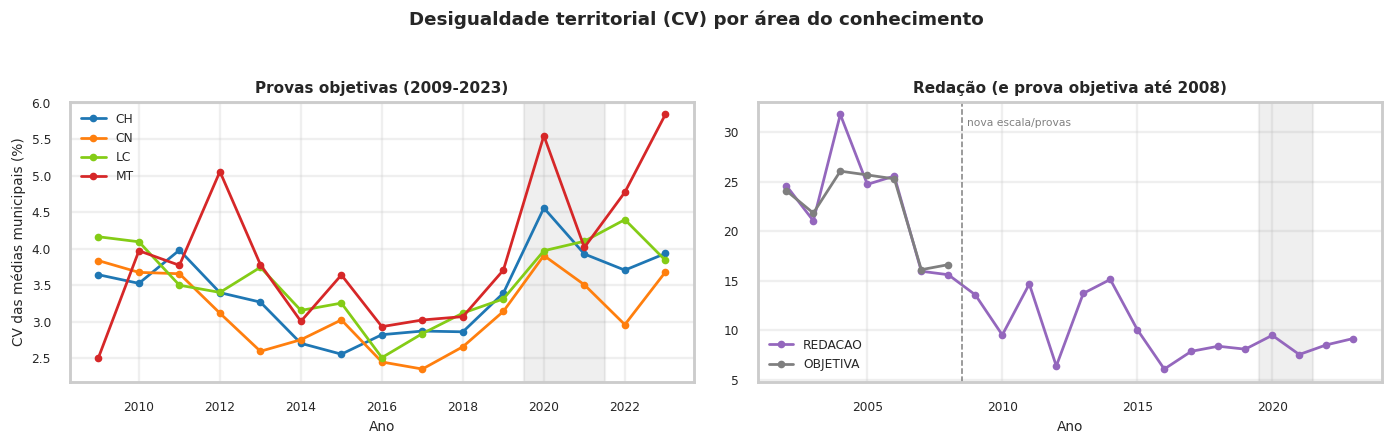

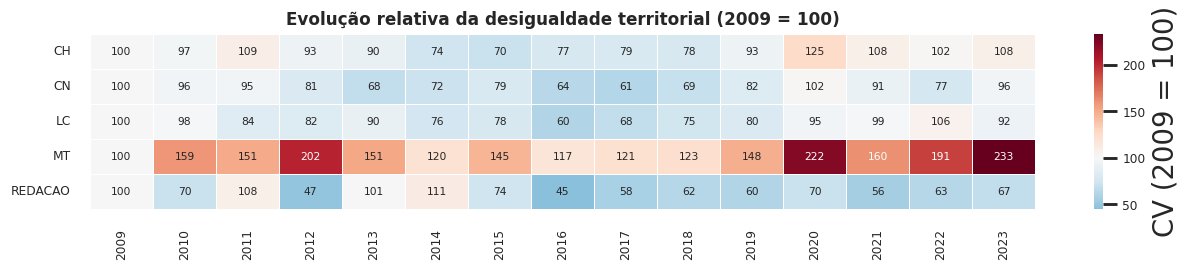

In [8]:
indicadores_t06 = desigualdade_t03.copy()
# display(indicadores_t06.pivot_table(
#     index="ano", columns="disciplina",
#     values=["cv_municipal_pct", "gini_medias_municipais", "p90_p10"],
# ))


t = indicadores_t06.copy()

CORES = {"CH": "#1f77b4", "CN": "#ff7f0e", "LC": "#84cc16", "MT": "#d62728", "REDACAO": "#9467bd","OBJETIVA": "#7f7f7f"}


fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

# Painel A: áreas objetivas
ax = axes[0]
for disc in ["CH", "CN", "LC", "MT"]:
    s = t[t.disciplina == disc].sort_values("ano")
    ax.plot(s.ano, s.cv_municipal_pct, marker="o", ms=4, lw=1.8,
            color=CORES[disc], label=disc)
ax.set_title("Provas objetivas (2009-2023)", fontsize=10, fontweight="bold")

# Painel B: redação, com OBJETIVA da era antiga
ax = axes[1]
for disc in ["REDACAO", "OBJETIVA"]:
    s = t[t.disciplina == disc].sort_values("ano")
    ax.plot(s.ano, s.cv_municipal_pct, marker="o", ms=4, lw=1.8,
            color=CORES[disc], label=disc)
ax.axvline(2008.5, color="gray", ls="--", lw=1)
ax.text(2008.7, ax.get_ylim()[1] * 0.95, "nova escala/provas", fontsize=7, color="gray", va="top")
ax.set_title("Redação (e prova objetiva até 2008)", fontsize=10, fontweight="bold")

for ax in axes:
    ax.axvspan(2019.5, 2021.5, color="gray", alpha=0.12)   # pandemia
    ax.set_xlabel("Ano", fontsize=9); ax.grid(alpha=0.3)
    ax.tick_params(labelsize=8); ax.legend(frameon=False, fontsize=8)
axes[0].set_ylabel("CV das médias municipais (%)", fontsize=9)
fig.suptitle("Desigualdade territorial (CV) por área do conhecimento",
             fontsize=12, fontweight="bold")
plt.tight_layout(); plt.show()


n = t[t.ano >= 2009].pivot(index="disciplina", columns="ano", values="cv_municipal_pct")
n = n.dropna(how="all").loc[["CH", "CN", "LC", "MT", "REDACAO"]]
idx = n.div(n[2009], axis=0) * 100

plt.figure(figsize=(12, 2.8))
ax = sns.heatmap(idx, annot=True, fmt=".0f", cmap="RdBu_r", center=100,
                 annot_kws={"fontsize": 7}, linewidths=0.5, linecolor="white",
                 cbar_kws={"label": "CV (2009 = 100)"})
ax.set_title("Evolução relativa da desigualdade territorial (2009 = 100)",
             fontsize=11, fontweight="bold")
ax.set_xlabel(""); ax.set_ylabel("")
ax.tick_params(labelsize=8)
ax.figure.axes[-1].tick_params(labelsize=8)
plt.tight_layout(); plt.show()

### Comentários

A análise de dispersão anual de T06 reproduz os mesmos indicadores apresentados na tabela T03. Assim, T06 deve ser interpretada como uma leitura temporal desses indicadores, e não como uma evidência independente.

A comparação do coeficiente de variação (CV) entre 2009 e 2023 resume os principais movimentos:

| Disciplina | CV em 2009 | CV em 2023 | Síntese |
| ---------- | ----------:| ----------:| -------------------- |
| CH         | 3,64%      | 3,93%      | Pequena ampliação |
| CN         | 3,84%      | 3,68%      | Pequena redução |
| LC         | 4,16%      | 3,84%      | Redução |
| MT         | 2,50%      | 5,84%      | Ampliação expressiva |
| Redação    | 13,57%     | 9,16%      | Redução relativa |

A trajetória anual não foi monotônica. Em 2020, o CV aumentou em CH, CN, LC e MT em relação a 2019. Em Matemática, a dispersão já havia apresentado uma elevação expressiva em 2012, quando atingiu 5,06%, e voltou a crescer nos anos finais, chegando a 5,84% em 2023, o maior valor da série. Esse comportamento também é observado no intervalo interquartil (IQR), que passou de 14,91 pontos em 2009 para 37,57 em 2023, indicando maior afastamento entre os valores centrais das distribuições municipais.

Em Ciências Humanas, o CV apresentou redução até 2015, mas voltou a aumentar nos anos seguintes, especialmente em 2020. Em 2023, alcançou 3,93%, ligeiramente acima do valor de 2009. Em Ciências da Natureza e Linguagens, apesar das oscilações anuais, os valores finais ficaram abaixo dos observados no início da série. 

Na Redação, o CV diminuiu de 13,57% em 2009 para 9,16% em 2023. Entretanto, essa redução não foi contínua: após atingir valores inferiores a 7% em alguns anos, voltou a crescer entre 2022 e 2023.

A desigualdade territorial evoluiu de forma distinta entre as disciplinas. Matemática é o principal ponto de atenção, apresentando ampliação expressiva da dispersão entre as médias municipais, especialmente nos anos finais da série. Ciências Humanas também terminou o período com dispersão ligeiramente superior à inicial. Em contrapartida, Ciências da Natureza e Linguagens apresentaram reduções relativas, enquanto a Redação, apesar de manter um CV superior ao das demais disciplinas, registrou redução expressiva em relação a 2009.

Esses resultados indicam que não houve uma trajetória única de convergência ou divergência territorial no desempenho. A evolução depende da disciplina e do período considerado. Como os indicadores são calculados sobre as médias municipais, eles descrevem a variabilidade entre municípios, não a dispersão das notas individuais dos participantes. Além disso, as diferenças anuais no número de municípios considerados devem ser levadas em conta na interpretação dos resultados.

## 7. Municípios com maior participação também apresentam melhores resultados?


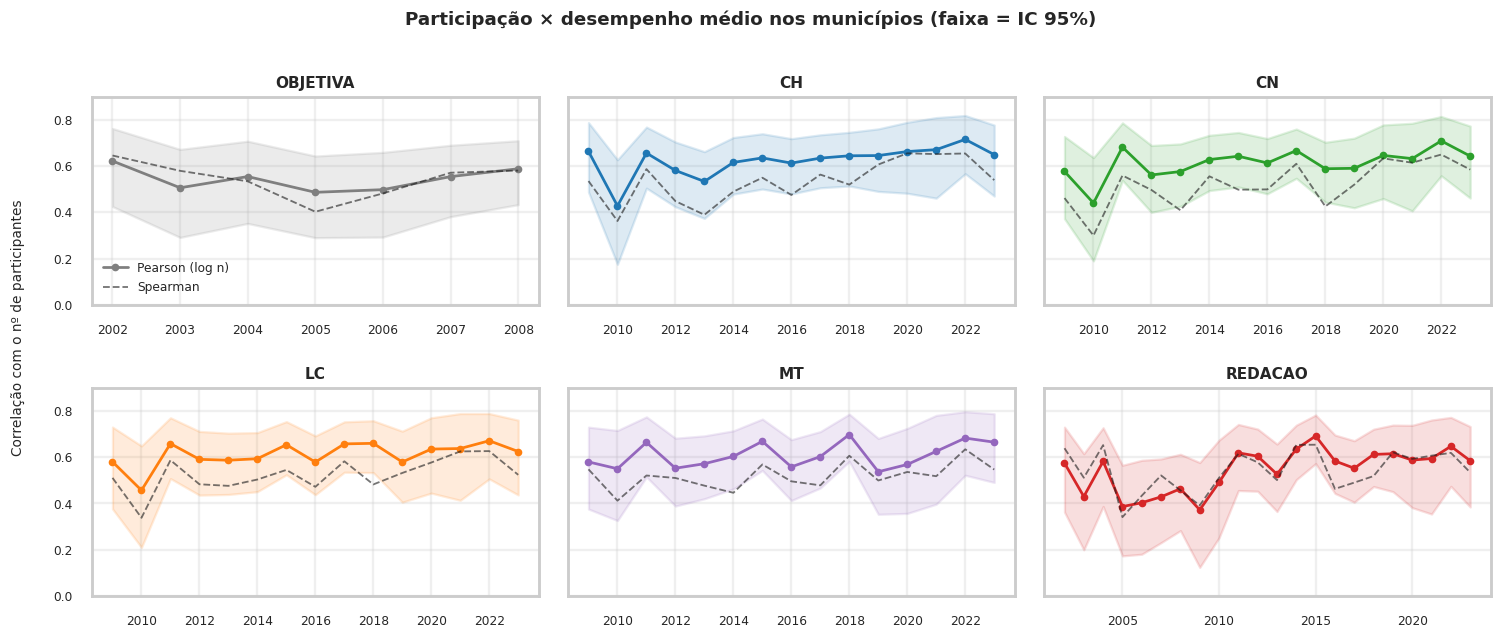

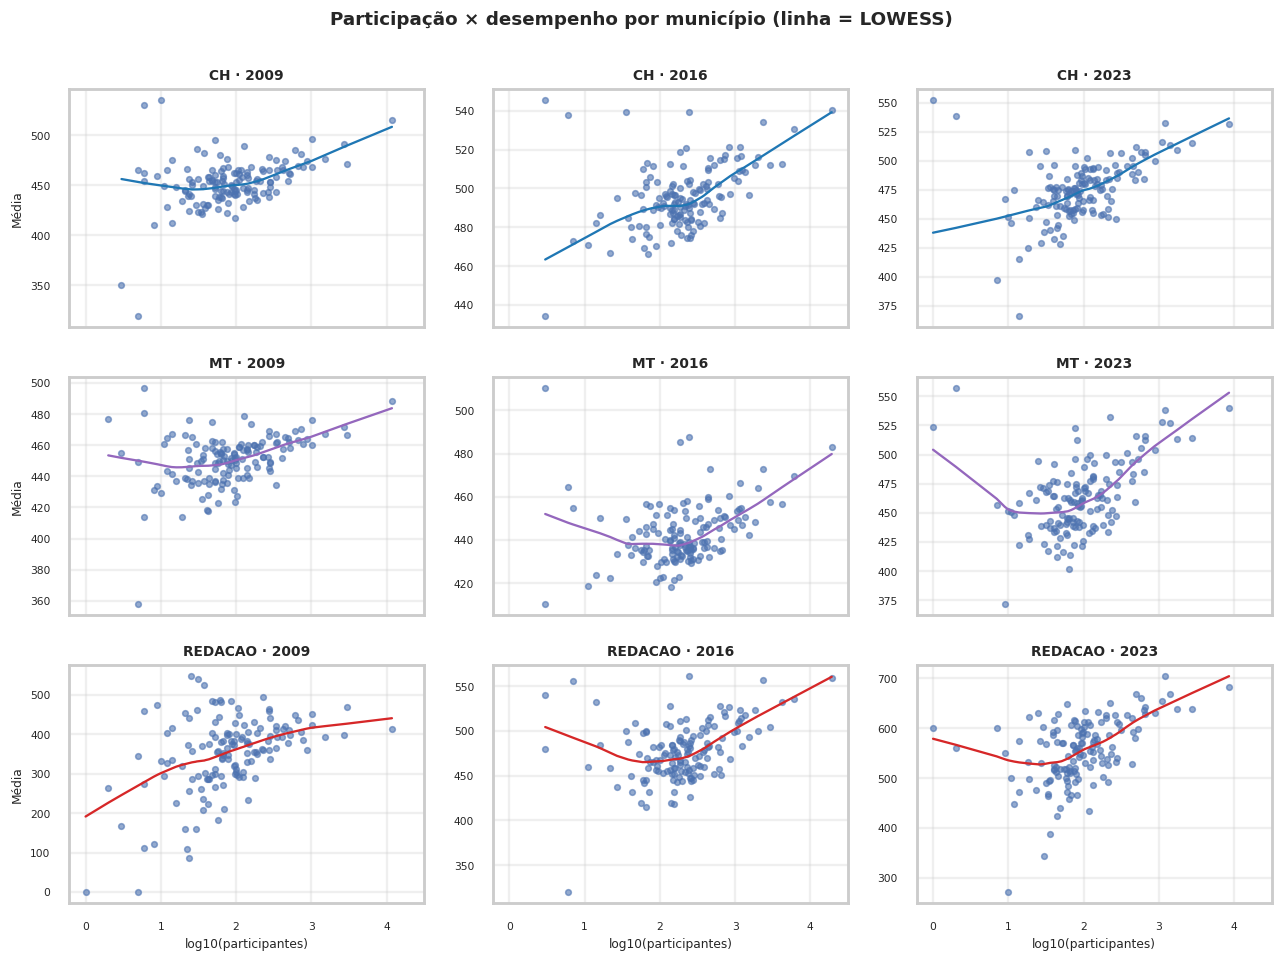

In [9]:
relacao_t07 = eda2.calcular_relacao_participacao_desempenho(desempenho_municipal)

t = relacao_t07.copy()
cores = {"CH": "#1f77b4", "CN": "#2ca02c", "LC": "#ff7f0e",
         "MT": "#9467bd", "REDACAO": "#d62728", "OBJETIVA": "#7f7f7f"}

# Intervalo de confiança de 95% (transformação de Fisher), usando n_municipios
def ic_fisher(r, n):
    z, se = np.arctanh(r), 1 / np.sqrt(n - 3)
    return np.tanh(z - 1.96 * se), np.tanh(z + 1.96 * se)

t["lo"], t["hi"] = ic_fisher(t["pearson_log_n_media"], t["n_municipios"])

discs = ["OBJETIVA", "CH", "CN", "LC", "MT", "REDACAO"]
fig, axes = plt.subplots(2, 3, figsize=(14, 6), sharey=True)

for ax, disc in zip(axes.flat, discs):
    s = t[t.disciplina == disc].sort_values("ano")
    ax.fill_between(s.ano, s.lo, s.hi, color=cores[disc], alpha=0.15)
    ax.plot(s.ano, s.pearson_log_n_media, marker="o", ms=4, lw=1.8,
            color=cores[disc], label="Pearson (log n)")
    ax.plot(s.ano, s.spearman_n_media, ls="--", lw=1.2, color="k",
            alpha=0.6, label="Spearman")
    ax.set_title(disc, fontsize=10, fontweight="bold")
    ax.grid(alpha=0.3); ax.tick_params(labelsize=8)
    ax.set_ylim(0, 0.9)


axes[0, 0].legend(frameon=False, fontsize=8)
fig.supylabel("Correlação com o nº de participantes", fontsize=9)
fig.suptitle("Participação × desempenho médio nos municípios (faixa = IC 95%)",
             fontsize=12, fontweight="bold")
plt.tight_layout(); plt.show()
d = desempenho_municipal.copy()
anos = [2009, 2016, 2023]
discs = ["CH", "MT", "REDACAO"]


curvas_lowess = {}  # crie antes do `for i, disc...`
fig, axes = plt.subplots(len(discs), len(anos), figsize=(12, 9),
                         sharex=True, squeeze=False)
for i, disc in enumerate(discs):
    for j, ano in enumerate(anos):
        ax = axes[i, j]
        s = d[(d.disciplina == disc) & (d.ano == ano)]

        sns.regplot(data=s, x=np.log10(s.n_participantes), y="media_ponderada",
                    ax=ax, scatter_kws={"s": 14, "alpha": 0.6},
                    line_kws={"color": cores[disc], "lw": 1.5}, lowess=True)
        
        ax.set_title(f"{disc} · {ano}", fontsize=9, fontweight="bold")
        ax.set_xlabel("log10(participantes)" if i == len(discs) - 1 else "", fontsize=8)
        ax.set_ylabel("Média" if j == 0 else "", fontsize=8)
        ax.tick_params(labelsize=7); ax.grid(alpha=0.3)
plt.suptitle("Participação × desempenho por município (linha = LOWESS)",
             fontsize=12, fontweight="bold")
plt.tight_layout(); plt.show()

### Comentários

As correlações de Pearson, Spearman e Pearson entre o logaritmo do número de participantes e a média municipal foram positivas em todos os anos e disciplinas apresentados. Considerando a mediana anual dos coeficientes entre 2009 e 2023, os resultados foram:

| Disciplina | Pearson (N, média) | Spearman (N, média) | Pearson (log N, média) |
| ---------- | ------------------:| -------------------:| ----------------------:|
| CH         | 0,469              | 0,540               | 0,645                  |
| CN         | 0,461              | 0,520               | 0,628                  |
| LC         | 0,454              | 0,524               | 0,625                  |
| MT         | 0,469              | 0,518               | 0,603                  |
| Redação    | 0,381              | 0,528               | 0,583                  |

Os resultados indicam uma associação positiva entre o número de participantes e a média municipal: municípios com maior participação tendem, em termos gerais, a apresentar médias mais elevadas. Essa associação é mais intensa quando o número de participantes é transformado pelo logaritmo. Em todas as disciplinas, a mediana de Pearson calculada com logaritmo é superior à correlação calculada com o número absoluto de participantes.

A correlação de Spearman também apresenta valores positivos, indicando que a associação não se restringe à relação linear entre as variáveis. Na Redação, por exemplo, a mediana de Spearman (0,528) é superior à de Pearson com o número absoluto de participantes (0,381), enquanto a correlação com logaritmo alcança 0,583.

**Variação temporal da associação**

A evolução dos coeficientes anuais mostra que a associação não permanece constante. Em CH, CN, LC e MT, a correlação de Pearson com logaritmo apresenta oscilações ao longo de 2009–2023. Em 2022, por exemplo, os coeficientes atingem valores relativamente elevados: 0,716 em CH, 0,709 em CN, 0,671 em LC e 0,683 em MT. Em 2023, os valores recuam para 0,650, 0,643, 0,625 e 0,665, respectivamente.

Na Redação, a associação também varia. O coeficiente de Pearson com logaritmo passa de 0,372 em 2009 para 0,692 em 2015, recuando para 0,585 em 2023. Portanto, embora a associação seja positiva, sua intensidade apresenta diferenças entre os anos.

Os intervalos de confiança de 95% calculados para Pearson com logaritmo ajudam a representar a incerteza das estimativas. Sua amplitude varia conforme o número de municípios considerados em cada ano, que também não é constante. Nas quatro áreas do conhecimento, por exemplo, a quantidade de municípios varia de 42 a 108 no período analisado.

**Formato da relação: curvas LOWESS**

As curvas LOWESS de CH, MT e Redação, apresentadas para 2009, 2016 e 2023, acrescentam uma informação que não aparece diretamente nos coeficientes de correlação: a relação entre participação e média municipal pode apresentar comportamento não linear.

- CH: em 2009, a curva apresenta uma pequena queda inicial, seguida de recuperação. Em 2016, predomina uma tendência crescente, com um trecho relativamente estável na região intermediária. Em 2023, a tendência é predominantemente crescente ao longo da faixa observada.
- MT: em 2009, observa-se uma curva com formato de U pouco acentuado. Em 2016, esse comportamento fica mais evidente, com redução inicial das médias e posterior recuperação. Em 2023, a curva também apresenta formato de U, com crescimento mais pronunciado na parte superior da distribuição de participantes.
- Redação: em 2009, a curva apresenta tendência crescente. Em 2016 e 2023, observa-se uma redução inicial, seguida de recuperação das médias conforme aumenta o número de participantes.

Esses formatos indicam que uma única relação linear pode não representar adequadamente todos os recortes. Entretanto, as curvas correspondem a três anos selecionados e a três disciplinas; não permitem generalizar o mesmo comportamento para todas as áreas ou para todos os anos.


Existe uma associação positiva entre participação e desempenho médio municipal no Pará. Municípios com maior número de participantes tendem a apresentar médias mais elevadas, e essa associação é mais expressiva quando o número de participantes é considerado em escala logarítmica. As curvas LOWESS mostram, adicionalmente, que essa relação pode assumir formatos distintos entre disciplinas e anos, incluindo comportamentos curvilíneos. Assim, o aumento da participação não está associado a uma variação uniforme das médias em toda a distribuição municipal.

É importante ressaltar que esses resultados são descritivos. A correlação não demonstra que o aumento do número de participantes provoque melhoria no desempenho. Características demográficas, socioeconômicas, educacionais e territoriais podem estar relacionadas simultaneamente à participação e às médias municipais. Portanto, a análise reforça a importância de considerar o porte e a cobertura dos municípios na comparação dos resultados do ENEM. As médias municipais devem ser interpretadas levando em conta o número de participantes e a possível não linearidade dessa relação, sem atribuir a ela uma explicação causal.

## 8. Síntese dos resultados


Os resultados evidenciam desigualdades territoriais no desempenho dos participantes do ENEM no Pará. Essas diferenças aparecem tanto nos níveis das médias municipais quanto na evolução temporal, na dispersão dos resultados e na distribuição dos melhores posicionamentos entre os municípios.

**Evolução das médias estaduais**

Entre 2009 e 2023, as médias ponderadas estaduais aumentaram nas cinco disciplinas, mas em magnitudes diferentes. Redação e Matemática apresentaram as maiores variações entre os extremos da série, enquanto Ciências da Natureza registrou a menor. Esse crescimento, entretanto, não ocorreu de forma linear e não representa necessariamente uma melhoria generalizada entre os municípios. A redução da cobertura municipal elegível nos anos finais também limita a comparação territorial ao longo do período.

**Estabilidade temporal das médias municipais**

A estabilidade das médias municipais variou conforme a disciplina. Ciências da Natureza e Linguagens apresentaram menor variação relativa ao longo do período, enquanto Redação registrou a maior oscilação temporal. Isso significa que as médias municipais de Redação sofreram maiores variações entre os anos. Esse resultado não indica, por si só, um desempenho inferior, mas uma menor estabilidade temporal em comparação às demais disciplinas.

**Dispersão do desempenho entre municípios**

A desigualdade territorial, medida pela dispersão relativa das médias municipais, apresentou comportamentos distintos entre as disciplinas.

* Matemática se destacou pelo aumento expressivo da dispersão entre 2009 e 2023, tornando-se o principal ponto de atenção nesse aspecto. Ciências Humanas apresentou pequena ampliação, enquanto Ciências da Natureza e Linguagens registraram reduções.

* Redação também apresentou redução da dispersão em relação a 2009, mas continuou sendo a disciplina com maior dispersão entre as médias municipais em 2023.

**Evolução do desempenho nos municípios**

A comparação dos 48 municípios presentes nos dois extremos da série, 2009 e 2023, mostrou que o crescimento das médias estaduais não foi acompanhado por todos os municípios. Em Ciências Humanas, Ciências da Natureza, Linguagens e Matemática, foram identificados municípios com redução das médias no período. Em Redação, por outro lado, todos os municípios comparáveis apresentaram aumento. Portanto, a elevação das médias estaduais não significa que todos os municípios tenham melhorado seu desempenho.

**Concentração dos melhores resultados**

Os rankings mostram que os melhores posicionamentos se concentram recorrentemente em um conjunto de municípios. Belém e Castanhal estiveram entre os dez primeiros em todos os anos analisados nas quatro disciplinas pós-2009. Ananindeua também apresentou elevada recorrência.

Outros municípios se destacaram em disciplinas específicas: Paragominas, Tucuruí e Parauapebas apareceram entre os melhores posicionados em diferentes áreas, enquanto Santarém teve presença especialmente frequente no Top 10 de Redação. Esses resultados, entretanto, estão condicionados ao critério de elegibilidade adotado e não representam necessariamente a totalidade dos municípios paraenses.

**Participação e desempenho municipal**

Foi identificada uma associação positiva entre o número de participantes e a média municipal. Em geral, municípios com maior número de participantes apresentaram médias mais elevadas. Essa associação foi mais intensa quando o número de participantes foi considerado em escala logarítmica. As curvas LOWESS também indicaram que o formato dessa relação varia conforme a disciplina e o ano. Como se trata de uma associação descritiva, os resultados não permitem afirmar que o aumento da participação cause melhoria no desempenho.

 <div style="background-color: #E2E8F0; padding: 12px; border-radius: 6px;">
    
**Síntese Final**  
As desigualdades territoriais no ENEM no Pará aparecem tanto nas diferenças entre as médias municipais quanto na evolução e na dispersão dos resultados. Matemática se destaca pelo aumento da dispersão relativa entre os municípios, enquanto Redação apresenta a maior dispersão em 2023 e a maior oscilação temporal. A concentração recorrente dos melhores posicionamentos em determinados municípios também evidencia que os resultados mais elevados não estão distribuídos uniformemente pelo território. Além disso, o aumento das médias estaduais não representa uma melhoria generalizada: em quatro disciplinas, houve municípios com redução das médias entre 2009 e 2023.Essas conclusões devem ser interpretadas considerando o critério de elegibilidade de mais de 100 participantes, a variação da cobertura municipal e o caráter descritivo das análises.

</div>
